# Stock Forecasting: CatBoost vs XGBoost vs LightGBM

Perbandingan model untuk memprediksi **kebutuhan stok 7 hari ke depan** (`required_stock_7d`) per outlet dan item, memakai `ML/data/Stock.csv`.

Target dan fitur mengikuti artefak `stock_prediction` yang sudah dipakai API (`API/app/models/stock_prediction.py`), supaya hasil notebook bisa dibandingkan dengan model yang berjalan di produksi.

**Catatan data:** `StockOut` adalah penjualan yang tercatat, bukan permintaan sebenarnya. Karena `OpeningStock + StockIn - StockOut = ClosingStock`, penjualan terpotong saat stok habis (censored demand). Tidak ada baris dengan `ClosingStock` negatif, dan `StockIn` hanya terisi di 12,5% baris.

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)

DATA_DIR = next(p for p in [Path.cwd() / "../data", Path.cwd() / "ML/data"] if (p / "Stock.csv").exists())
stock = pd.read_csv(DATA_DIR / "Stock.csv", parse_dates=["Date"])
items = pd.read_csv(DATA_DIR / "ItemMaster.csv")

print(f"{len(stock):,} baris | {stock.Date.min():%Y-%m-%d} .. {stock.Date.max():%Y-%m-%d} | "
      f"{stock.Outlet.nunique()} outlet x {stock.ItemID.nunique()} item x {stock.Date.nunique()} hari")
print(f"missing: {int(stock.isna().sum().sum())} | closing stock negatif: {int((stock.ClosingStock < 0).sum())}")
stock.head()

76,704 baris | 2025-01-02 .. 2025-09-30 | 3 outlet x 94 item x 272 hari
missing: 0 | closing stock negatif: 0


,Date,Outlet,ItemID,OpeningStock,StockIn,StockOut,ClosingStock,MinimumStock
0,2025-01-02,SHOP001,P001,15,0,2,13,5
1,2025-01-03,SHOP001,P001,13,0,1,12,5
2,2025-01-04,SHOP001,P001,12,0,0,12,5
3,2025-01-05,SHOP001,P001,12,0,3,9,5
4,2025-01-06,SHOP001,P001,9,0,2,7,5


## Fitur dan target

Target `required_stock_7d` = total `StockOut` pada t+1 sampai t+7. Fitur hanya memakai informasi yang diketahui sampai hari t:

- kalender: `dow`, `day`, `month`, `is_weekend`
- lag `StockOut`: `lag7`, `lag14`, `lag28`
- rata-rata bergerak: `roll7`, `roll28`
- `product_avg`: rata-rata historis series sampai t
- `Outlet` dan `ItemID` sebagai categorical

Baris dengan lag/rolling belum lengkap dibuang, begitu juga 7 hari terakhir yang targetnya belum tersedia. Split dilakukan berdasarkan tanggal (bukan acak) agar tidak ada kebocoran dari masa depan.

In [2]:
FEATURES = ["dow", "day", "month", "is_weekend", "lag7", "lag14", "lag28", "roll7", "roll28", "product_avg"]
CATEGORICAL = ["Outlet", "ItemID"]
TARGET = "required_stock_7d"
SPLIT_DATE = "2025-08-31"


def build_dataset(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.sort_values(["Outlet", "ItemID", "Date"]).reset_index(drop=True)
    by_series = frame.groupby(["Outlet", "ItemID"], sort=False)

    data = frame[["Date", "Outlet", "ItemID", "StockOut"]].copy()
    for lag in (7, 14, 28):
        data[f"lag{lag}"] = by_series.StockOut.shift(lag)
    for window in (7, 28):
        data[f"roll{window}"] = by_series.StockOut.transform(lambda s: s.shift(1).rolling(window).mean())
    data["product_avg"] = by_series.StockOut.transform(lambda s: s.shift(1).expanding().mean())
    data[TARGET] = by_series.StockOut.transform(lambda s: s.shift(-1).rolling(7).sum().shift(-6))

    data["dow"] = data.Date.dt.dayofweek
    data["day"] = data.Date.dt.day
    data["month"] = data.Date.dt.month
    data["is_weekend"] = (data.dow >= 5).astype(int)
    return data.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)


dataset = build_dataset(stock)
categories = {col: sorted(dataset[col].unique()) for col in CATEGORICAL}
for col in CATEGORICAL:
    dataset[col] = pd.Categorical(dataset[col], categories=categories[col])

train = dataset[dataset.Date <= SPLIT_DATE]
test = dataset[dataset.Date > SPLIT_DATE]
X_train, y_train = train[FEATURES + CATEGORICAL], train[TARGET]
X_test, y_test = test[FEATURES + CATEGORICAL], test[TARGET]

print(f"train {len(train):,} baris (s.d. {train.Date.max():%Y-%m-%d}) | test {len(test):,} baris "
      f"({test.Date.min():%Y-%m-%d} .. {test.Date.max():%Y-%m-%d})")
print(f"target: mean {dataset[TARGET].mean():.2f} | median {dataset[TARGET].median():.0f} | max {dataset[TARGET].max():.0f}")

train 60,348 baris (s.d. 2025-08-31) | test 6,486 baris (2025-09-01 .. 2025-09-23)
target: mean 5.49 | median 5 | max 19


## Metrik

Sama dengan `regression_metrics` di `API/app/models/common.py`: MAE, RMSE, dan WAPE (total error dibagi total aktual, jadi tidak bias ke item dengan volume besar). Baseline **seasonal-naive** = total `StockOut` 7 hari terakhir, untuk melihat apakah model benar-benar menambah nilai.

In [3]:
def score(actual, predicted) -> dict:
    actual, predicted = np.asarray(actual, float), np.clip(np.asarray(predicted, float), 0, None)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "WAPE": np.abs(actual - predicted).sum() / np.abs(actual).sum(),
    }


results = {"Seasonal-naive (baseline)": {"metrics": score(y_test, test.roll7 * 7), "seconds": 0.0,
                                        "prediction": test.roll7.values * 7}}

MODELS = {
    "CatBoost": lambda: CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, cat_features=CATEGORICAL,
                                          verbose=0, random_seed=42, allow_writing_files=False, thread_count=-1),
    "XGBoost": lambda: XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, enable_categorical=True,
                                    tree_method="hist", n_jobs=-1, random_state=42),
    "LightGBM": lambda: LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, verbose=-1,
                                      n_jobs=-1, random_state=42),
}

for name, factory in MODELS.items():
    model = factory()
    started = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    prediction = np.clip(model.predict(X_test), 0, None)
    results[name] = {"metrics": score(y_test, prediction), "seconds": elapsed, "prediction": prediction, "model": model}
    print(f"{name:<26} selesai dalam {elapsed:5.2f}s")

CatBoost                   selesai dalam  2.85s


XGBoost                    selesai dalam  2.47s


LightGBM                   selesai dalam  1.52s


## Hasil perbandingan

In [4]:
comparison = pd.DataFrame({name: {**result["metrics"], "train_seconds": result["seconds"]}
                           for name, result in results.items()}).T
comparison = comparison.sort_values("MAE")
comparison["MAE"] = comparison["MAE"].round(3)
comparison["RMSE"] = comparison["RMSE"].round(3)
comparison["WAPE"] = (comparison["WAPE"] * 100).round(2).astype(str) + "%"
comparison["train_seconds"] = comparison["train_seconds"].round(2)
comparison

,MAE,RMSE,WAPE,train_seconds
CatBoost,1.723,2.189,34.14%,2.85
LightGBM,1.810,2.318,35.86%,1.52
XGBoost,1.832,2.348,36.3%,2.47
Seasonal-naive (baseline),2.376,3.043,47.08%,0.00


In [5]:
per_outlet = pd.DataFrame({
    name: test.assign(error=np.abs(y_test - result["prediction"])).groupby("Outlet", observed=True).error.mean()
    for name, result in results.items()
}).round(3)
per_outlet.index.name = "MAE per outlet"
per_outlet

,Seasonal-naive (baseline),CatBoost,XGBoost,LightGBM
MAE per outlet,,,,
SHOP001,2.805,2.108,2.303,2.275
SHOP002,1.886,1.307,1.388,1.348
SHOP003,2.437,1.755,1.805,1.806


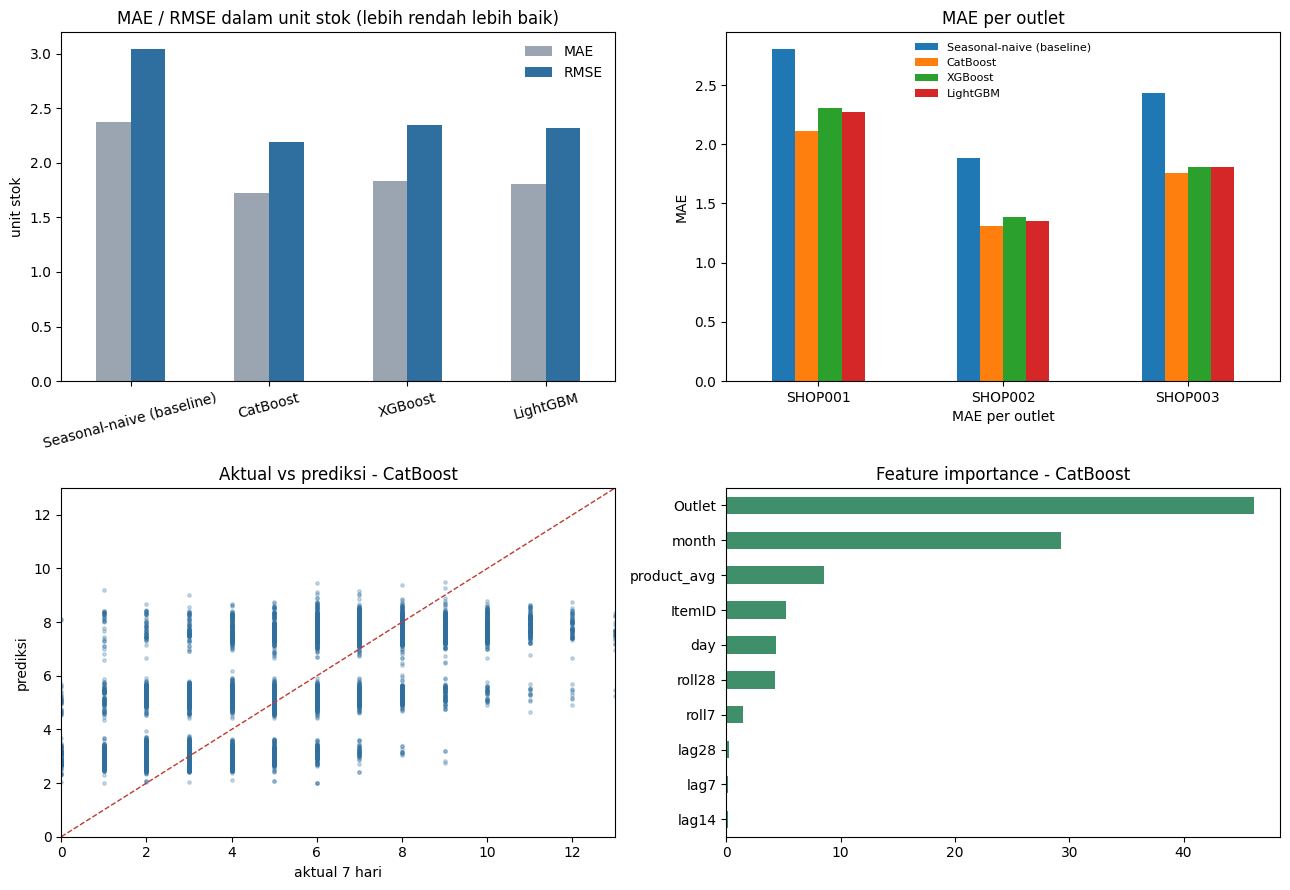

In [6]:
best_name = comparison.index[0]
best = results[best_name]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

names = list(results)
colors = ["#9aa5b1", "#2f6f9f", "#3f8f6b", "#b4762a"]

metric_frame = pd.DataFrame({name: result["metrics"] for name, result in results.items()}).T
metric_frame[["MAE", "RMSE"]].plot.bar(ax=axes[0, 0], color=colors[:2], rot=15)
axes[0, 0].set_title("MAE / RMSE dalam unit stok (lebih rendah lebih baik)")
axes[0, 0].set_ylabel("unit stok")
axes[0, 0].legend(frameon=False)

per_outlet.plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set_title("MAE per outlet")
axes[0, 1].set_ylabel("MAE")
axes[0, 1].legend(frameon=False, fontsize=8)

axes[1, 0].scatter(y_test, best["prediction"], s=6, alpha=0.25, color="#2f6f9f")
limit = float(np.percentile(y_test, 99.5))
axes[1, 0].plot([0, limit], [0, limit], color="#c0392b", linewidth=1, linestyle="--")
axes[1, 0].set_xlim(0, limit)
axes[1, 0].set_ylim(0, limit)
axes[1, 0].set_title(f"Aktual vs prediksi - {best_name}")
axes[1, 0].set_xlabel("aktual 7 hari")
axes[1, 0].set_ylabel("prediksi")

importance = pd.Series(best["model"].feature_importances_, index=FEATURES + CATEGORICAL).sort_values()
importance.tail(10).plot.barh(ax=axes[1, 1], color="#3f8f6b")
axes[1, 1].set_title(f"Feature importance - {best_name}")

fig.tight_layout()
plt.show()

## Kesimpulan

Sel di bawah mencetak ringkasan otomatis dari hasil di atas: model terbaik, selisihnya terhadap baseline, dan model tercepat.

In [7]:
baseline_mae = results["Seasonal-naive (baseline)"]["metrics"]["MAE"]
gain = (baseline_mae - best["metrics"]["MAE"]) / baseline_mae * 100

print(f"Model terbaik     : {best_name} (MAE {best['metrics']['MAE']:.3f}, WAPE {best['metrics']['WAPE']:.1%})")
print(f"vs baseline naive : MAE turun {gain:.1f}% (baseline {baseline_mae:.3f})")
timing = comparison.drop(index="Seasonal-naive (baseline)").train_seconds
print("Waktu training    : " + ", ".join(f"{name} {value}s" for name, value in timing.items()) + "")
print()
print("Catatan: target adalah kebutuhan stok 7 hari, bukan permintaan sebenarnya.")
print("StockOut terpotong saat stok habis, jadi model cenderung meremehkan item yang sering kosong.")
print("Gunakan prediksi sebagai input reorder point, dan tetap jaga safety stock minimum di MinimumStock.")
print("Prediksi mengumpul di beberapa nilai per series: demand hampir i.i.d., model praktis mempelajari rata-rata series + kalender.")

Model terbaik     : CatBoost (MAE 1.723, WAPE 34.1%)
vs baseline naive : MAE turun 27.5% (baseline 2.376)
Waktu training    : CatBoost 2.85s, LightGBM 1.52s, XGBoost 2.47s

Catatan: target adalah kebutuhan stok 7 hari, bukan permintaan sebenarnya.
StockOut terpotong saat stok habis, jadi model cenderung meremehkan item yang sering kosong.
Gunakan prediksi sebagai input reorder point, dan tetap jaga safety stock minimum di MinimumStock.
Prediksi mengumpul di beberapa nilai per series: demand hampir i.i.d., model praktis mempelajari rata-rata series + kalender.
